# Figura 4.1 - Validación cruzada inicial de candidatos

Genera una figura compacta para justificar la selección de `P04 + XGBoost` como línea principal antes del tuning.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se pudo localizar la raiz del proyecto.")


project_root = find_project_root()
img_dir = project_root / "img"
img_dir.mkdir(parents=True, exist_ok=True)
output_path = img_dir / "fig_4_1_cv_candidatos_ams.png"

In [3]:
cv_results = pd.DataFrame(
    [
        {
            "candidato": "P04 + XGBoost",
            "ams_mean": 1.620982,
            "ams_std": 0.090305,
            "auc_mean": 0.912398,
        },
        {
            "candidato": "P02 + XGBoost",
            "ams_mean": 1.614261,
            "ams_std": 0.057094,
            "auc_mean": 0.911332,
        },
        {
            "candidato": "P04 + MLP",
            "ams_mean": 1.581468,
            "ams_std": 0.072190,
            "auc_mean": 0.910071,
        },
        {
            "candidato": "P01 + Random Forest",
            "ams_mean": 1.544423,
            "ams_std": 0.043274,
            "auc_mean": 0.906627,
        },
    ]
)
cv_results

,candidato,ams_mean,ams_std,auc_mean
0,P04 + XGBoost,1.620982,0.090305,0.912398
1,P02 + XGBoost,1.614261,0.057094,0.911332
2,P04 + MLP,1.581468,0.072190,0.910071
3,P01 + Random Forest,1.544423,0.043274,0.906627


PosixPath('/home/santig14/fing/taa/1_TallerAA/img/fig_4_1_cv_candidatos_ams.png')

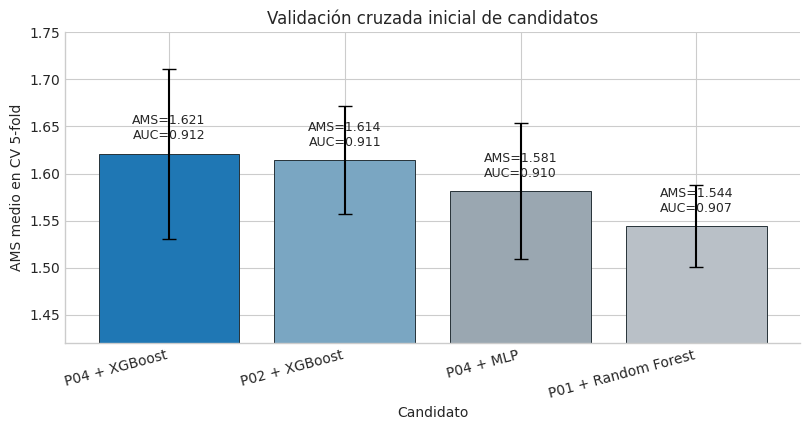

In [4]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8.2, 4.4))

colors = ["#1f77b4", "#7aa6c2", "#9aa7b1", "#b9c0c7"]
x = np.arange(len(cv_results))
bars = ax.bar(
    x,
    cv_results["ams_mean"],
    yerr=cv_results["ams_std"],
    capsize=5,
    color=colors,
    edgecolor="#263238",
    linewidth=0.7,
)

for bar, ams, auc in zip(bars, cv_results["ams_mean"], cv_results["auc_mean"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.012,
        f"AMS={ams:.3f}\nAUC={auc:.3f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.set_xticks(x)
ax.set_xticklabels(cv_results["candidato"], rotation=15, ha="right")
ax.set_ylabel("AMS medio en CV 5-fold")
ax.set_xlabel("Candidato")
ax.set_title("Validación cruzada inicial de candidatos")
ax.set_ylim(1.42, 1.75)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(output_path, dpi=220, bbox_inches="tight")
output_path